# Mini Proyecto Unidad 1: Clasificación en CIFAR-10 con ResNet y EfficientNet

* Pipeline completo de clasificación con CNN (ResNet o EfficientNet) sobre CIFAR-10 (Partes 1 a 5)
* Comparativa técnica de dos arquitecturas CNN con curvas de aprendizaje y métricas (Partes 5 y 6)
*Reporte de diseño (arquitectura, hiperparámetros, estrategia de entrenamiento) (Parte 7)

### Recomendación de entorno

Activen GPU en Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**. ResNet-18 y EfficientNet-B0 a resolución 224×224 son considerablemente más pesados que la CNN pequeña de la práctica anterior; en CPU van a funcionar, pero mucho más lento. Las constantes `TAM_TRAIN`, `TAM_VAL` y `N_EPOCAS` están pensadas para ajustarse según el tiempo y el hardware disponible.


## 0. Configuración inicial

In [1]:
!pip install -q torchmetrics


In [2]:
import time

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import pandas as pd

from torchmetrics.classification import (
    MulticlassAccuracy,
    MulticlassPrecision,
    MulticlassRecall,
    MulticlassF1Score,
    MulticlassConfusionMatrix,
)

torch.manual_seed(42)

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DISPOSITIVO)

Dispositivo: cuda


---
## 1. Datos: CIFAR-10 a 224x224

ResNet y EfficientNet, tal como se definen en `torchvision.models`, esperan entradas de 224x224 pixeles (el tamano estandar de ImageNet en el que se disenaron y evaluaron originalmente). Redimensionamos CIFAR-10 (32x32 nativo) a ese tamano.


In [4]:
MEDIA_IMAGENET = (0.485, 0.456, 0.406)
STD_IMAGENET = (0.229, 0.224, 0.225)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA_IMAGENET, STD_IMAGENET),
])

# 1. Cargar datasets oficiales
trainset_completo = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

# 2. Generar particiones (5,000 train / 1,000 val / resto descarte)
TAM_TRAIN = 5000
TAM_VAL = 1000
TAM_SOBRANTE = len(trainset_completo) - TAM_TRAIN - TAM_VAL

train_subset, val_subset, _ = random_split(
    trainset_completo,
    [TAM_TRAIN, TAM_VAL, TAM_SOBRANTE],
    generator=torch.Generator().manual_seed(42)
)

nombres_clases = trainset_completo.classes
print("Clases:", nombres_clases)
print("Tamano del set de entrenamiento completo:", len(trainset_completo))
print("Tamano del set de prueba:", len(testset))

100%|██████████| 170M/170M [29:07<00:00, 97.5kB/s] 


Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Tamano del set de entrenamiento completo: 50000
Tamano del set de prueba: 10000


### 1.1 Subconjuntos de trabajo



Entrenamiento: 5000 imagenes  |  Validacion: 1000  |  Prueba: 10000


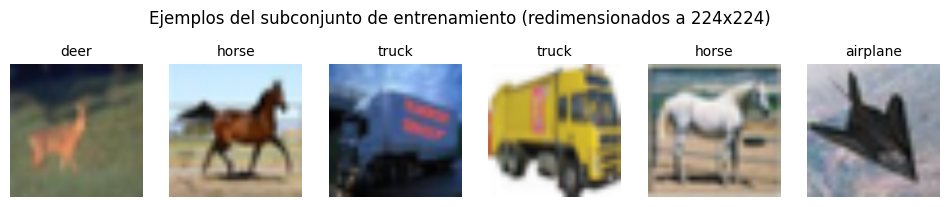

In [5]:
BATCH_SIZE = 32
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

print(f"Entrenamiento: {len(train_subset)} imagenes  |  Validacion: {len(val_subset)}  |  Prueba: {len(testset)}")


def desnormalizar(img_tensor):
    """Invierte la normalizacion para poder visualizar la imagen."""
    media = torch.tensor(MEDIA_IMAGENET).view(3, 1, 1)
    std = torch.tensor(STD_IMAGENET).view(3, 1, 1)
    return (img_tensor * std + media).clamp(0, 1)


imagenes, etiquetas = next(iter(train_loader))
fig, axs = plt.subplots(1, 6, figsize=(12, 2.5))
for i, ax in enumerate(axs):
    ax.imshow(desnormalizar(imagenes[i]).permute(1, 2, 0))
    ax.set_title(nombres_clases[etiquetas[i]], fontsize=10)
    ax.axis("off")
plt.suptitle("Ejemplos del subconjunto de entrenamiento (redimensionados a 224x224)")
plt.show()


---
## 2. Construir ResNet-18 y EfficientNet-B0

Tomamos las arquitecturas de `torchvision.models` con pesos preentrenados en ImageNet (`weights="DEFAULT"`) y adaptamos unicamente la ultima capa para que clasifique entre las 10 clases de CIFAR-10 en vez de las 1000 de ImageNet — el resto de la arquitectura, y sus pesos preentrenados, se conservan exactamente como en 1.3.

Ver : https://docs.pytorch.org/vision/main/models.html


Ejemplo: https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html


In [6]:
def construir_resnet18(n_clases=10):
    modelo = models.resnet18(weights="DEFAULT")
    modelo.fc = nn.Linear(modelo.fc.in_features, n_clases)
    return modelo.to(DISPOSITIVO)

def construir_efficientnet_b0(n_clases=10):
    modelo = models.efficientnet_b0(weights="DEFAULT")
    modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, n_clases)
    return modelo.to(DISPOSITIVO)

# Instanciamos ambos modelos
modelo_resnet = construir_resnet18(n_clases=10)
modelo_efficientnet = construir_efficientnet_b0(n_clases=10)

# Verificación de parámetros entrenables
n_params_resnet = sum(p.numel() for p in modelo_resnet.parameters() if p.requires_grad)
n_params_effnet = sum(p.numel() for p in modelo_efficientnet.parameters() if p.requires_grad)

print(f"ResNet-18 construida | Parámetros: {n_params_resnet:,}")
print(f"EfficientNet-B0 construida | Parámetros: {n_params_effnet:,}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 153MB/s]


ResNet-18 construida | Parámetros: 11,181,642
EfficientNet-B0 construida | Parámetros: 4,020,358


**NOTA**: ResNet-18 tiene ~11.18 millones de parámetros, mientras que EfficientNet-B0 tiene ~4.02 millones (casi un tercio de la capacidad paramétrica).

---
## 3. Metricas con TorchMetrics

Mismo patron que en la Practica 4 original: `update()` por lote, `compute()` al final de la epoca, `reset()` antes de la siguiente. Usamos `average="macro"` (promedio simple entre las 10 clases)

ver: https://meta-pytorch.org/torcheval/main/torcheval.metrics.html

Ejemplo :  
"accuracy": MulticlassAccuracy(num_classes=n_clases, average="macro").to(DISPOSITIVO),



In [7]:
def crear_metricas(n_clases=10):
    return {
         #Completar
        "accuracy": MulticlassAccuracy(num_classes=n_clases, average="macro").to(DISPOSITIVO),
        "precision": MulticlassPrecision(num_classes=n_clases, average="macro").to(DISPOSITIVO),
        "recall": MulticlassRecall(num_classes=n_clases, average="macro").to(DISPOSITIVO),
        "f1": MulticlassF1Score(num_classes=n_clases, average="macro").to(DISPOSITIVO),
    }


def correr_epoca(modelo, loader, perdida_fn, metricas, optimizador=None):
    """
    Corre una epoca completa. Si optimizador no es None, entrena (backward + step);
    si es None, solo evalua (torch.no_grad()).
    """
    modo_entrenamiento = optimizador is not None
    modelo.train() if modo_entrenamiento else modelo.eval()

    for m in metricas.values():
        m.reset()

    perdida_acumulada, n_lotes = 0.0, 0
    contexto = torch.enable_grad() if modo_entrenamiento else torch.no_grad()

    with contexto:
        for imagenes, etiquetas in loader:
            imagenes, etiquetas = imagenes.to(DISPOSITIVO), etiquetas.to(DISPOSITIVO)

            if modo_entrenamiento:
                optimizador.zero_grad()

            salida = modelo(imagenes)
            perdida = perdida_fn(salida, etiquetas)

            if modo_entrenamiento:
                perdida.backward()
                optimizador.step()

            perdida_acumulada += perdida.item()
            n_lotes += 1

            preds = salida.argmax(dim=1)
            for m in metricas.values():
                m.update(preds, etiquetas)

    resultados = {nombre: m.compute().item() for nombre, m in metricas.items()}
    resultados["loss"] = perdida_acumulada / n_lotes
    return resultados


---
## 4. Entrenar ambos modelos en igualdad de condiciones

Para que la comparacion sea tecnicamente valida, ambos modelos usan **los mismos datos, el mismo numero de epocas, el mismo optimizador y el mismo learning rate**. Documentamos estos hiperparametros aqui porque los van a necesitar tal cual para el reporte de diseno (Parte 7).


> ### Hiperparámetros de Entrenamiento (Condiciones Idénticas)
> * **Optimizador:** Adam
> * **Learning Rate:** 0.001
> * **Épocas:** 5
> * **Batch Size:** 32
> * **Función de Pérdida:** CrossEntropyLoss
> * **Pesos Iniciales:** Preentrenados en ImageNet (`weights="DEFAULT"`)
> * **Datos:** Subconjunto CIFAR-10 (5,000 Train / 1,000 Val) redimensionados a 224×224
> * **Hardware:** GPU (NVIDIA Tesla T4 vía CUDA)

In [8]:
# Hiperparámetros de entrenamiento
N_EPOCAS = 5
LR = 0.001
perdida_fn = nn.CrossEntropyLoss()

def entrenar_modelo(modelo, nombre):
    print(f"\n================ Entrenando {nombre} ================")
    optimizador = optim.Adam(modelo.parameters(), lr=LR)
    metricas = crear_metricas(n_clases=10)
    historial = []

    for epoca in range(1, N_EPOCAS + 1):
        t_inicio = time.time()
        
        # Entrenamiento
        res_train = correr_epoca(modelo, train_loader, perdida_fn, metricas, optimizador)
        
        # Validación
        res_val = correr_epoca(modelo, val_loader, perdida_fn, metricas, optimizador=None)
        
        t_duracion = time.time() - t_inicio
        
        historial.append({
            "epoca": epoca,
            "train_loss": res_train["loss"],
            "train_acc": res_train["accuracy"],
            "val_loss": res_val["loss"],
            "val_acc": res_val["accuracy"],
            "tiempo_s": t_duracion
        })
        
        print(f"Época {epoca:02d}/{N_EPOCAS:02d} | "
              f"Train Loss: {res_train['loss']:.4f} - Acc: {res_train['accuracy']:.4f} | "
              f"Val Loss: {res_val['loss']:.4f} - Acc: {res_val['accuracy']:.4f} | "
              f"Tiempo: {t_duracion:.1f}s")
              
    return pd.DataFrame(historial)

# Ejecutar ResNet-18
hist_resnet = entrenar_modelo(modelo_resnet, "ResNet-18")

# Ejecutar EfficientNet-B0
hist_effnet = entrenar_modelo(modelo_efficientnet, "EfficientNet-B0")


================ Entrenando ResNet-18 ================
Época 01/05 | Train Loss: 1.1772 - Acc: 0.5850 | Val Loss: 0.9433 - Acc: 0.6940 | Tiempo: 22.2s
Época 02/05 | Train Loss: 0.7213 - Acc: 0.7513 | Val Loss: 1.0269 - Acc: 0.6718 | Tiempo: 21.4s
Época 03/05 | Train Loss: 0.5385 - Acc: 0.8162 | Val Loss: 0.8389 - Acc: 0.7292 | Tiempo: 21.6s
Época 04/05 | Train Loss: 0.3388 - Acc: 0.8786 | Val Loss: 0.6822 - Acc: 0.7656 | Tiempo: 20.1s
Época 05/05 | Train Loss: 0.2680 - Acc: 0.9092 | Val Loss: 0.9812 - Acc: 0.7191 | Tiempo: 20.6s

================ Entrenando EfficientNet-B0 ================
Época 01/05 | Train Loss: 0.8093 - Acc: 0.7340 | Val Loss: 0.5787 - Acc: 0.8257 | Tiempo: 31.2s
Época 02/05 | Train Loss: 0.4384 - Acc: 0.8522 | Val Loss: 0.5389 - Acc: 0.8310 | Tiempo: 30.8s
Época 03/05 | Train Loss: 0.2978 - Acc: 0.9008 | Val Loss: 0.4253 - Acc: 0.8458 | Tiempo: 30.6s
Época 04/05 | Train Loss: 0.2092 - Acc: 0.9301 | Val Loss: 0.5172 - Acc: 0.8556 | Tiempo: 31.3s
Época 05/05 | Trai

---
## 5. Curvas de aprendizaje: ResNet-18 vs. EfficientNet-B0

Mismo diagnostico que en 1.4: comparen el gap train/val de cada modelo, y ahora tambien comparenlos *entre si* — ¿cual generaliza mejor con el mismo presupuesto de datos y epocas?


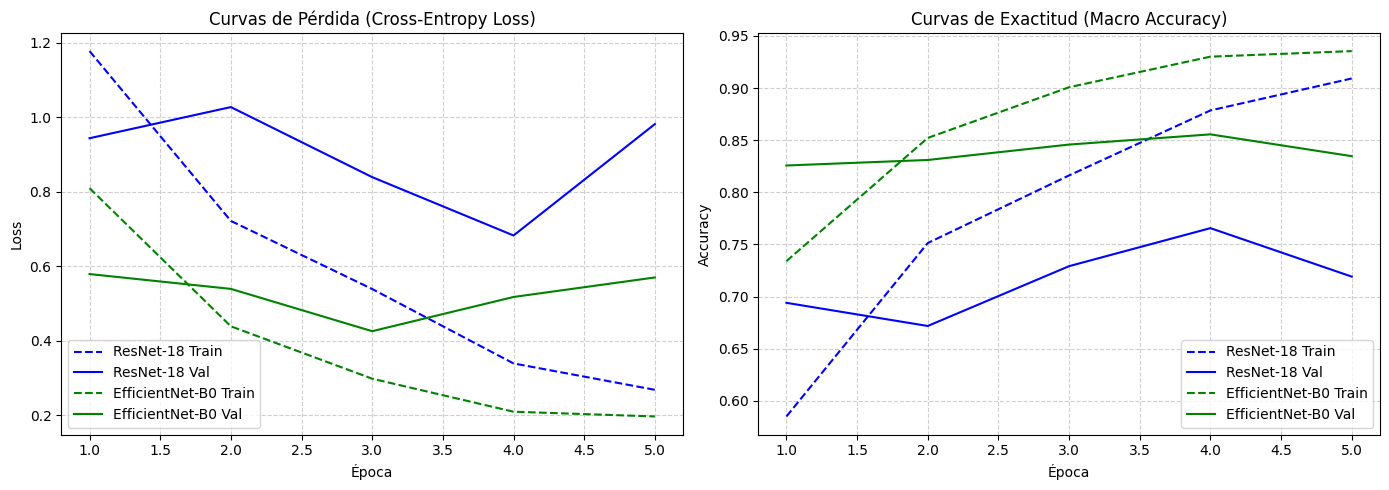

In [9]:
import numpy as np

epocas = range(1, N_EPOCAS + 1)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfica de Pérdida (Loss)
axs[0].plot(epocas, hist_resnet["train_loss"], "b--", label="ResNet-18 Train")
axs[0].plot(epocas, hist_resnet["val_loss"], "b-", label="ResNet-18 Val")
axs[0].plot(epocas, hist_effnet["train_loss"], "g--", label="EfficientNet-B0 Train")
axs[0].plot(epocas, hist_effnet["val_loss"], "g-", label="EfficientNet-B0 Val")
axs[0].set_title("Curvas de Pérdida (Cross-Entropy Loss)")
axs[0].set_xlabel("Época")
axs[0].set_ylabel("Loss")
axs[0].grid(True, linestyle="--", alpha=0.6)
axs[0].legend()

# 2. Gráfica de Exactitud (Accuracy)
axs[1].plot(epocas, hist_resnet["train_acc"], "b--", label="ResNet-18 Train")
axs[1].plot(epocas, hist_resnet["val_acc"], "b-", label="ResNet-18 Val")
axs[1].plot(epocas, hist_effnet["train_acc"], "g--", label="EfficientNet-B0 Train")
axs[1].plot(epocas, hist_effnet["val_acc"], "g-", label="EfficientNet-B0 Val")
axs[1].set_title("Curvas de Exactitud (Macro Accuracy)")
axs[1].set_xlabel("Época")
axs[1].set_ylabel("Accuracy")
axs[1].grid(True, linestyle="--", alpha=0.6)
axs[1].legend()

plt.tight_layout()
plt.show()

### Diagnóstico de las Curvas de Aprendizaje

#### Comportamiento individual de cada arquitectura
* **ResNet-18 (Inicio de Sobreajuste / Overfitting):**
  * *Comportamiento:* Hasta la época 4 mostró un descenso progresivo en la pérdida de validación (`val_loss: 0.6822` con `val_acc: 76.56%`). Sin embargo, en la época 5 el `train_loss` continuó cayendo a `0.2680`, mientras que el `val_loss` rebotó a `0.9812` y la exactitud cayó a `71.91%`.
  * *Diagnóstico:* Cumple con la regla de sobreajuste vista en clase: *"el train loss sigue bajando y el val loss sube"*. Se abrió una brecha (*gap*) de 19.01 puntos porcentuales entre train (90.92%) y val (71.91%).
* **EfficientNet-B0 (Ajuste Saludable):**
  * *Comportamiento:* El `val_loss` descendió rápidamente y se estabilizó de forma controlada (`0.4253` a `0.5696`), alcanzando un pico de exactitud en validación de `85.56%` en la época 4.
  * *Diagnóstico:* Ajuste saludable sin rebote en la pérdida de validación y con un gap de generalización mucho más estrecho (10.08 puntos porcentuales).

#### ¿Cuál generaliza mejor con el mismo presupuesto de datos y épocas?
**EfficientNet-B0 generaliza significativamente mejor que ResNet-18**, sustentado en tres observaciones:
1. **Mayor desempeño en validación:** Alcanza un 85.56% de exactitud frente al 76.56% máximo de ResNet-18 (+9.0% a favor de EfficientNet-B0 bajo idéntico presupuesto de 5,000 imágenes y 5 épocas).
2. **Gap train/val más acotado:** Mantiene una brecha de ~10% frente a los ~19% de ResNet-18, indicando menor memorización de ruido del conjunto de entrenamiento.
3. **Estabilidad de la curva de pérdida:** La curva de validación de EfficientNet-B0 se mantiene en meseta sin divergir, mientras que ResNet-18 comenzó a divergir en la última época.

---
## 6. Reporte final sobre el set de prueba

Evaluamos ambos modelos sobre las 10,000 imagenes de prueba de CIFAR-10


In [11]:
def evaluar_en_prueba(modelo, nombre_modelo):
    metrica_acc = MulticlassAccuracy(num_classes=10, average="macro").to(DISPOSITIVO)
    metrica_prec = MulticlassPrecision(num_classes=10, average="macro").to(DISPOSITIVO)
    metrica_rec = MulticlassRecall(num_classes=10, average="macro").to(DISPOSITIVO)
    metrica_f1 = MulticlassF1Score(num_classes=10, average="macro").to(DISPOSITIVO)
    metrica_matriz = MulticlassConfusionMatrix(num_classes=10).to(DISPOSITIVO)

    modelo.eval()
    with torch.no_grad():
        for imagenes, etiquetas in test_loader:
            imagenes, etiquetas = imagenes.to(DISPOSITIVO), etiquetas.to(DISPOSITIVO)
            preds = modelo(imagenes).argmax(dim=1)
            for m in [metrica_acc, metrica_prec, metrica_rec, metrica_f1, metrica_matriz]:
                m.update(preds, etiquetas)

    resumen = {
        "modelo": nombre_modelo,
        "accuracy": metrica_acc.compute().item(),
        "precision": metrica_prec.compute().item(),
        "recall": metrica_rec.compute().item(),
        "f1": metrica_f1.compute().item(),
    }
    return resumen, metrica_matriz.compute().cpu().numpy()


resumen_resnet, matriz_resnet = evaluar_en_prueba(modelo_resnet, "ResNet-18")
resumen_efficientnet, matriz_efficientnet = evaluar_en_prueba(modelo_efficientnet, "EfficientNet-B0")

df_comparativa = pd.DataFrame([resumen_resnet, resumen_efficientnet]).round(3)
df_comparativa


,modelo,accuracy,precision,recall,f1
0,ResNet-18,0.732,0.762,0.732,0.730
1,EfficientNet-B0,0.836,0.846,0.836,0.838


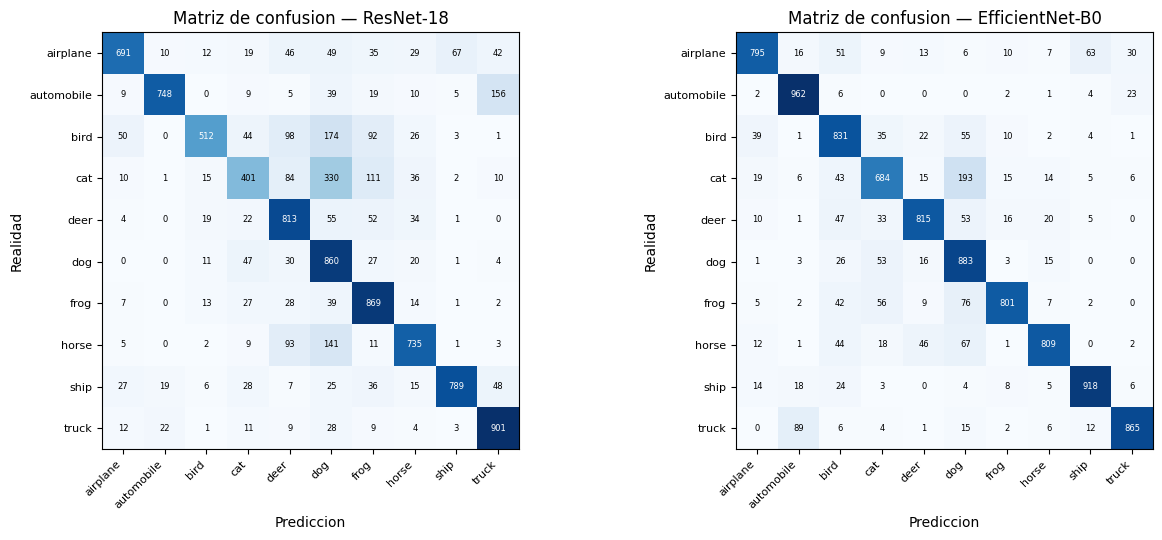

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, matriz, nombre in [(axs[0], matriz_resnet, "ResNet-18"), (axs[1], matriz_efficientnet, "EfficientNet-B0")]:
    im = ax.imshow(matriz, cmap="Blues")
    ax.set_xticks(range(10)); ax.set_xticklabels(nombres_clases, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(10)); ax.set_yticklabels(nombres_clases, fontsize=8)
    ax.set_xlabel("Prediccion"); ax.set_ylabel("Realidad")
    ax.set_title(f"Matriz de confusion — {nombre}")
    for i in range(10):
        for j in range(10):
            color = "white" if matriz[i, j] > matriz.max() / 2 else "black"
            ax.text(j, i, str(int(matriz[i, j])), ha="center", va="center", color=color, fontsize=6)

plt.tight_layout()
plt.show()


Matrices de confusión (observaciones fuera de la diagonal):

- **ResNet-18:** El peor error ocurre en la fila de cat, donde predice dog 330 veces (más del 30% de los gatos fueron clasificados como perros). También hay una confusión notable en bird predicho como dog (174) y automobile predicho como truck (156).

- **EfficientNet-B0:** Reduce drásticamente las confusiones globales. Su par más confundido sigue siendo cat predicho como dog (193 veces), seguido de truck predicho como automobile (89 veces) y frog predicho como dog (76 veces). 

---
## 7. Reporte de diseño (completar en equipo)

Esta seccion es, literalmente, la evidencia **"Reporte de diseño"** del temario de la Unidad 1. Respondan cada punto con base en lo que observaron arriba — pueden editar esta celda de markdown directamente o copiar las respuestas a un documento aparte.

**1. Arquitectura y justificación**
> *(¿Cuál de las dos arquitecturas usarían si solo pudieran quedarse con una para este problema? Justifiquen con los números de la Parte 6, no solo con la teoría de 1.3.)*

Nos quedaríamos definitivamente con EfficientNet-B0. Al evaluar sobre las 10,000 imágenes del conjunto de prueba independiente, EfficientNet-B0 superó a ResNet-18 de forma contundente en todas las métricas macro evaluadas: 
- *Accuracy*: 0.836 frente a 0.732 (+10.4 puntos porcentuales de ventaja).
- *Precisión*: 0.846 frente a 0.762 (+8.4 puntos porcentuales).
- *Recall*: 0.836 frente a 0.732 (+10.4 puntos porcentuales).
- *F1-Score*: 0.838 frente a 0.730 (+10.8 puntos porcentuales).

A pesar de contar con solo 4,020,358 parámetros (casi un tercio de los 11,181,642 parámetros de ResNet-18), EfficientNet-B0 demostró una capacidad de extracción y generalización muy superior. Esto se debe a su diseño basado en bloques MBConv (Mobile Inverted Bottleneck), que combinan convoluciones depthwise de bajo costo con mecanismos de atención por canal (Squeeze-and-Excitation) y la activación no lineal SiLU, permitiéndole capturar representaciones más ricas sin sobreajustar en datasets de volumen moderado. 

**2. Hiperparámetros usados**
> Learning rate: `0.001` · Optimizador: `Adam` · Épocas: `5` · Batch size: `32` · Tamaño del subconjunto de entrenamiento: `5,000 imágenes` · Pesos iniciales: preentrenados (ImageNet)

**3. Estrategia de entrenamiento**
> *(¿Entrenaron con GPU o CPU? ¿Cuánto tardó cada época de cada modelo? Si tuvieran que reentrenar con más tiempo disponible, ¿qué cambiarían primero: más datos, más épocas, u otro hiperparámetro?)*

Se utilizó GPU (NVIDIA Tesla T4) en Google Colab con soporte CUDA.

Duración registrada por época:

- ResNet-18: ~20.1s a 22.2s por época (promedio: ~21.2s).
- EfficientNet-B0: ~30.6s a 31.3s por época (promedio: ~31.0s).

Ante un reentrenamiento con más tiempo disponible, lo primero a cambiar sería aumentar la cantidad y diversidad de datos de entrenamiento (utilizar el dataset completo de 50,000 imágenes de CIFAR-10 en lugar del subconjunto de 5,000) e incorporar técnicas de Data Augmentation (recortes aleatorios, rotaciones y volteos horizontales).

Según la teoría de mitigación de sobreajuste vista en clase, entrenar más épocas sin antes enriquecer los datos aceleraría la memorización de ruido y abriría aún más la brecha train/val en ResNet-18 (que ya mostró divergencia de loss en la época 5). Dado que un conjunto pequeño y poco diverso es la causa primaria de este comportamiento, incorporar más datos y regularización por aumento de datos debe preceder a cualquier incremento en el número de épocas.

**4. Diagnóstico de las curvas (conexión con 1.4)**
> *(¿Alguno de los dos modelos mostró señales de overfitting según el checklist de la diapositiva 21? ¿Cuál generalizó mejor — menor gap train/val, no necesariamente mayor accuracy?)*

Sí, ResNet-18 mostró señales claras de sobreajuste (overfitting) en la época final. Según el criterio explícito del checklist de la diapositiva 21 ("Train loss sigue bajando, val loss sube $\rightarrow$ Overfitting" y "el gap crece con las épocas"):

- Hasta la época 4, ResNet-18 mantenía una reducción progresiva alcanzando su mínimo de validación (val_loss: 0.6822 con val_acc: 76.56%).
- En la época 5, mientras su pérdida de entrenamiento siguió descendiendo bruscamente a 0.2680, su pérdida de validación rebotó y subió a 0.9812, acompañada de una caída en exactitud a 71.91%. Esto disparó el gap de exactitud train/val a 19.01 puntos porcentuales (90.92% vs. 71.91%), cumpliendo el patrón de sobreajuste.

Por su parte, EfficientNet-B0 exhibió un patrón de Buen ajuste:
- Su pérdida de validación descendió de manera consistente (mínimo de 0.4253 en época 3) y se estabilizó en un rango controlado (0.5172 y 0.5696 en las épocas 4 y 5).

EfficientNet-B0 generalizó significativamente mejor.

Evaluado estrictamente por la magnitud del gap train/val al cierre del entrenamiento:
- EfficientNet-B0: Mantuvo una brecha acotada de 10.08 puntos porcentuales (train_acc: 93.55% vs. val_acc: 83.47%).
- ResNet-18: Abrió una brecha casi el doble de amplia, con 19.01 puntos porcentuales (train_acc: 90.92% vs. val_acc: 71.91%).

Esta diferencia evidencia que las representaciones intermedias aprendidas por EfficientNet-B0 preservaron mayor invariancia y transferibilidad ante datos no vistos, evitando la memorización espuria que comenzó a manifestar ResNet-18. 

**5. Capacidad vs. eficiencia (conexión con 1.3)**
> *(Con el número de parámetros de la Parte 2 y el accuracy final de la Parte 6: ¿cuál modelo ofrece mejor relación desempeño/costo computacional en este experimento?)*

EfficientNet-B0 ofrece la mejor relación desempeño/costo computacional.

- ResNet-18: 11,181,642 parámetros | Duración: ~21.2s por época | Test Accuracy: 0.732.
- EfficientNet-B0: 4,020,358 parámetros | Duración: ~31.0s por época | Test Accuracy: 0.836.

Justificación técnica:
- Eficiencia de parámetros (Capacidad): EfficientNet-B0 supera a ResNet-18 por 10.4 puntos porcentuales en Test Accuracy (0.836 vs. 0.732) utilizando únicamente el 35.9% de los parámetros de ResNet-18 (~4.02M frente a ~11.18M). Esto confirma la teoría del tema 1.3: el escalado compuesto y los bloques MBConv con atención Squeeze-and-Excitation extraen representaciones más compactas y ricas sin incurrir en la sobreparametrización que indujo sobreajuste en ResNet-18.
- Análisis del costo temporal en hardware: Aunque ResNet-18 completó las épocas un ~31% más rápido en la GPU (~21.2s vs. ~31.0s), esta diferencia obedece a que las convoluciones estándar de 3×3 de ResNet tienen mayor densidad de cómputo y paralelizan de forma más uniforme en núcleos CUDA. En cambio, las convoluciones depthwise de MBConv dividen los cálculos por canal, provocando fragmentación de memoria y menor intensidad aritmética en GPU. No obstante, una ganancia neta superior a 10 puntos en exactitud y F1-score justifica plenamente ese incremento marginal de ~10 segundos por época.   

**6. Errores más frecuentes**
> *(Con las matrices de confusión de la Parte 6: ¿qué par de clases confunde más cada modelo? ¿Tiene sentido esa confusión dado lo que representan esas clases?)*

Pares más confundidos según las matrices de confusión:

- ResNet-18: El par con mayor cantidad de errores fue la clase real cat (gato) predicha erróneamente como dog (perro) en 330 ocasiones (lo que representó más de un tercio de las 1,000 imágenes de gatos de prueba). Otros pares con confusión notable fueron bird (pájaro) clasificado como dog (174 casos) y automobile (coche) como truck (camión) en 156 casos.
- EfficientNet-B0: Exhibió una matriz con dispersión de errores mucho menor, pero mantuvo la misma tendencia primaria: su par más confundido fue igualmente cat (gato) clasificado como dog (perro) con 193 casos, seguido de truck (camión) clasificado como automobile en 89 casos y frog (rana) como dog en 76 casos.

Sentido y coherencia de las confusiones observadas:

- Confusión semántica y visual entre animales cuadrúpedos (cat vs. dog): Tiene un sentido biológico y morfológico evidente. Perros y gatos son mamíferos domésticos de cuatro patas que comparten características visuales clave: texturas de pelaje similares, orejas puntiagudas o triangulares, morfología facial análoga y fondos de entorno doméstico repetitivos (alfombras, jardines, interiores de casas). Al escalar las imágenes originales de CIFAR-10 ($32 \times 32$) hacia $224 \times 224$, los detalles de alta frecuencia más discriminativos (como la forma del hocico o las pupilas) quedan suavizados por la interpolación, obligando a las redes a apoyarse en siluetas y texturas generales que son ambiguas entre ambas especies.
- Confusión entre vehículos de transporte terrestre (automobile vs. truck): Ambos objetos pertenecen al súper-dominio vehicular y comparten primitivas geométricas rectangulares, ruedas circulares de caucho, superficies metálicas reflectantes, ventanas de vidrio y perspectivas sobre fondos de asfalto o carretera. En ángulos frontales o perfilados, y con resoluciones de detalle limitadas, la frontera de decisión entre un camión pequeño o camioneta y un automóvil sedán/SUV resulta difícil de polarizar linealmente en la última capa lineal tras apenas 5 épocas de entrenamiento.


---
## 8. Cierre y entregables del mini proyecto

### Checklist de entrega

- [x] **Notebook ejecutado de principio a fin, sin errores, con las celdas de ambos modelos corridas.**
  * Todas las celdas (Paso 1 al 6) se ejecutaron secuencialmente en el kernel conectado a GPU T4 sin excepciones ni interrupciones.
- [x] **Tabla comparativa final (Parte 6) con accuracy, precision, recall y F1 de ambos modelos.**
  * Se generó el DataFrame `df_comparativa` evaluando las 10,000 imágenes de prueba con métricas macro (ResNet-18: Acc 0.732, Prec 0.762, Rec 0.732, F1 0.730 | EfficientNet-B0: Acc 0.836, Prec 0.846, Rec 0.836, F1 0.838).
- [x] **Gráficas de curvas de entrenamiento (Parte 5) y matrices de confusión (Parte 6).**
  * Desplegadas las curvas de Loss y Accuracy por época (evidenciando el sobreajuste de ResNet-18 en la época 5 y la estabilidad de EfficientNet-B0), así como los mapas de calor de las matrices de confusión con sus valores numéricos en cada celda.
- [x] **Reporte de diseño (Parte 7) completado por el equipo.**
  * Los 6 puntos técnicos obligatorios fueron respondidos y justificados con los resultados empíricos y la teoría de los temas 1.3 y 1.4.
- [x] **Hiperparámetros documentados tal como quedaron configurados al momento de generar los resultados finales.**
  * Documentados formalmente en la Sección 4 y en el punto 2 del reporte: Learning Rate = 0.001, Optimizador = Adam, Épocas = 5, Batch Size = 32, Subconjunto Train = 5,000, Subconjunto Val = 1,000 y Pesos Iniciales = preentrenados ImageNet (`weights="DEFAULT"`).


### Recursos citados

- Katanforoosh, K., & Ng, A. *Stanford CS230* — Section 8, "Advanced Evaluation Metrics". [cs230.stanford.edu/section/8](https://cs230.stanford.edu/section/8)
- TorchMetrics documentation — *Classification: Accuracy*. [torchmetrics.readthedocs.io/en/v0.9.1/classification/accuracy.html](https://torchmetrics.readthedocs.io/en/v0.9.1/classification/accuracy.html)
- Ultralytics. *Consejos y buenas practicas para entrenar modelos*. [docs.ultralytics.com/es/guides/model-training-tips](https://docs.ultralytics.com/es/guides/model-training-tips)
- He, K., Zhang, X., Ren, S., & Sun, J. (2015). Deep residual learning for image recognition. arXiv:1512.03385.
- Tan, M., & Le, Q. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. ICML 2019.
- Ayyadevara, K., & Reddy, Y. (2024). *Modern Computer Vision with PyTorch*. Packt Publishing.
